# Lab 1 — Training Neural Networks with Keras (Completed)

Original: UofT-DSI/deep_learning, `01_materials/labs/lab_1.ipynb`. The practical uses **scikit-learn `load_digits()` (1,797 images of 8 × 8 pixels)**, despite the original introduction mentioning 28 × 28 MNIST.

> **Environment:** Python 3.11, TensorFlow 2.16.2 (Intel Mac), NumPy, scikit-learn, pandas, matplotlib. Select your `.venv311` kernel in VS Code and run cells from the top. These are **completed adapted versions** of the UofT-DSI Lab 1–3 materials, not byte-for-byte edits of the university's original notebooks.

## 1. Set up TensorFlow and load the handwritten-digit data

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential, initializers
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.utils import to_categorical

try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass
print('TensorFlow:', tf.__version__)
print('Python can train using the CPU.')
np.random.seed(42)
tf.random.set_seed(42)
digits = load_digits()
print('Images:', digits.images.shape)
print('Flattened data:', digits.data.shape)
print('Labels:', digits.target.shape)

2026-11-11 01:38:24.597251: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.16.2
Python can train using the CPU.
Images: (1797, 8, 8)
Flattened data: (1797, 64)
Labels: (1797,)


**Interpretation:** `digits.images.shape` is `(1797, 8, 8)`; `digits.data.shape` is `(1797, 64)`. Each image has 64 pixel values after flattening.

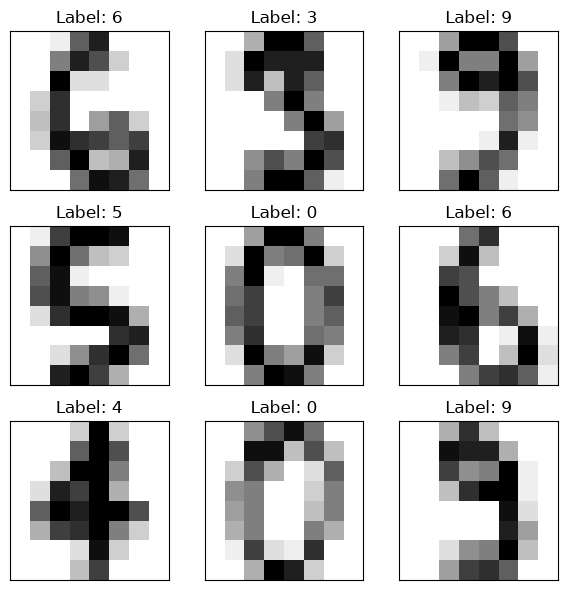

In [2]:
# Random handwritten digits, including their true labels.
random_indices = np.random.default_rng(42).choice(len(digits.images), 9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    index = random_indices[i]
    ax.imshow(digits.images[index], cmap='gray_r', interpolation='nearest')
    ax.set_title(f'Label: {digits.target[index]}')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

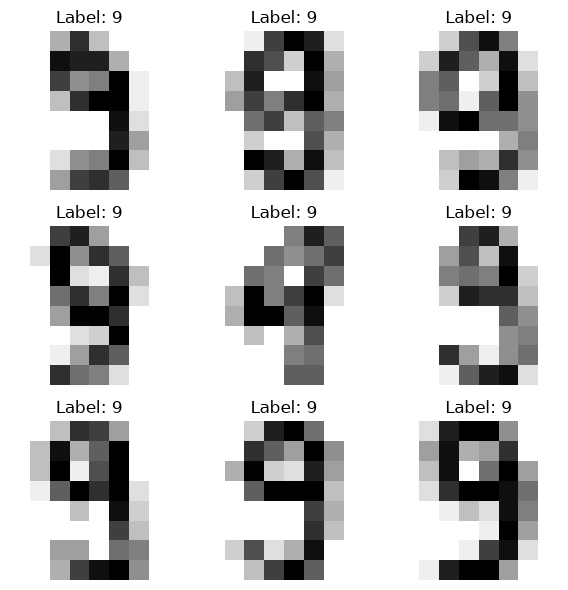

In [3]:
# Digits labelled 9 may still look different.
nine_indices = np.flatnonzero(digits.target == 9)
selected_nines = np.random.default_rng(21).choice(nine_indices, 9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for index, ax in zip(selected_nines, axes.flat):
    ax.imshow(digits.images[index], cmap='gray_r', interpolation='nearest')
    ax.set_title('Label: 9')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Train/test split and one-hot encoding

An 80/20 split reserves data the model did not use for training. One-hot encoding converts digit `3` into `[0,0,0,1,0,0,0,0,0,0]`.

In [4]:
X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    digits.data.astype('float32'), digits.target,
    test_size=0.2, random_state=42, stratify=digits.target
)
y_train = to_categorical(y_train_raw, num_classes=10)
y_test = to_categorical(y_test_raw, num_classes=10)
print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print('y_train:', y_train.shape, 'y_test:', y_test.shape)
print('Label example:', y_train_raw[0], 'as one-hot:', y_train[0])

X_train: (1437, 64) X_test: (360, 64)
y_train: (1437, 10) y_test: (360, 10)
Label example: 5 as one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 3. Build and train a feedforward neural network

The model has **two hidden Dense layers with 64 ReLU units** and an output layer with **10 softmax probabilities**.

In [5]:
def build_classifier(extra_hidden=False, initialization=None):
    layers = [Input(shape=(64,))]
    for _ in range(3 if extra_hidden else 2):
        kwargs = {'kernel_initializer': initialization} if initialization is not None else {}
        layers.append(Dense(64, activation='relu', **kwargs))
    layers.append(Dense(10, activation='softmax'))
    return Sequential(layers)

model = build_classifier()
model.compile(loss='categorical_crossentropy', optimizer=SGD(), metrics=['accuracy'])
model.summary()
history = model.fit(X_train, y_train, epochs=5, batch_size=32,
                    validation_split=0.2, verbose=1)
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Baseline test loss: {loss:.3f}, accuracy: {accuracy:.1%}')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,970 (35.04 KB)

 Trainable params: 8,970 (35.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5988 - loss: 1.6154 - val_accuracy: 0.7396 - val_loss: 0.8579
Epoch 2/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8642 - loss: 0.5005 - val_accuracy: 0.8472 - val_loss: 0.5909
Epoch 3/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9130 - loss: 0.3237 - val_accuracy: 0.8646 - val_loss: 0.4711
Epoch 4/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9391 - loss: 0.2386 - val_accuracy: 0.8819 - val_loss: 0.3989
Epoch 5/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9487 - loss: 0.1895 - val_accuracy: 0.8854 - val_loss: 0.3593
Baseline test loss: 0.278, accuracy: 93.1%


## 4. Inspect mistakes and predicted probabilities

Incorrect predictions: 25 / 360


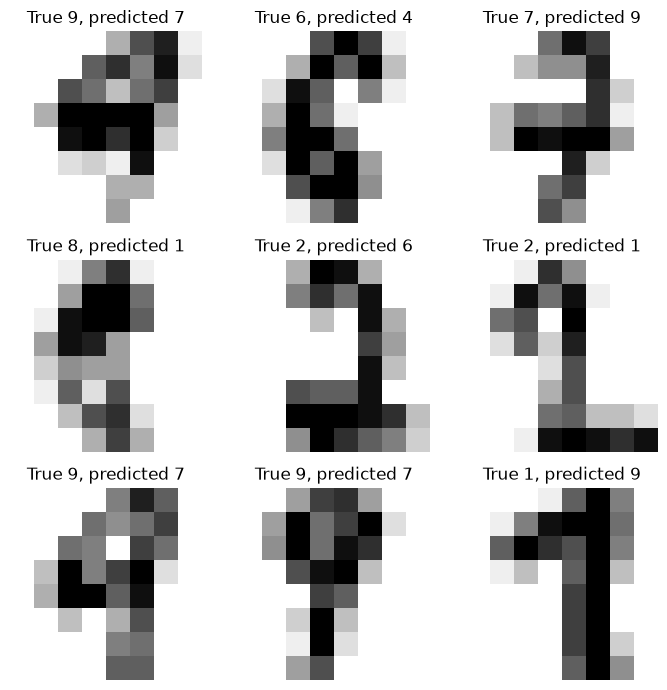

In [6]:
predictions = model.predict(X_test, verbose=0)
predicted_classes = np.argmax(predictions, axis=1)
wrong = np.flatnonzero(predicted_classes != y_test_raw)
print(f'Incorrect predictions: {len(wrong)} / {len(X_test)}')
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax, idx in zip(axes.flat, wrong[:9]):
    ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'True {y_test_raw[idx]}, predicted {predicted_classes[idx]}')
    ax.axis('off')
for ax in axes.flat[len(wrong[:9]):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Completed exercises: Optimizer comparison

**Questions from the lab:** What happens if SGD learning rate decreases or increases? How does momentum affect performance? Does Adam or an extra hidden layer improve results? We compare each condition using a **fresh independently trained model**, so experiments are not accidentally continued from previous weights.

In [7]:
optimizer_trials = []

def run_trial(label, opt, extra_hidden=False, epochs=5):
    candidate = build_classifier(extra_hidden=extra_hidden)
    candidate.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    trace = candidate.fit(X_train, y_train, epochs=epochs, batch_size=32,
                          validation_split=0.2, verbose=0)
    test_loss, test_acc = candidate.evaluate(X_test, y_test, verbose=0)
    optimizer_trials.append({'Setting': label, 'Test loss': test_loss,
                              'Test accuracy': test_acc, 'History': trace})
    print(f'{label:27s} | test accuracy {test_acc:.3f} | loss {test_loss:.3f}')
    return candidate

small_lr_model = run_trial('SGD learning rate 0.001', SGD(learning_rate=0.001))
large_lr_model = run_trial('SGD learning rate 0.1', SGD(learning_rate=0.1))
momentum_model = run_trial('SGD momentum 0.9', SGD(learning_rate=0.01, momentum=0.9))
adam_model = run_trial('Adam default', Adam())
extra_model = run_trial('Adam + third hidden layer', Adam(), extra_hidden=True)

SGD learning rate 0.001     | test accuracy 0.764 | loss 0.810
SGD learning rate 0.1       | test accuracy 0.311 | loss 1.800
SGD momentum 0.9            | test accuracy 0.942 | loss 0.161
Adam default                | test accuracy 0.936 | loss 0.223
Adam + third hidden layer   | test accuracy 0.919 | loss 0.222


,Setting,Test loss,Test accuracy
2,SGD momentum 0.9,0.161037,0.941667
3,Adam default,0.223282,0.936111
4,Adam + third hidden layer,0.221803,0.919444
0,SGD learning rate 0.001,0.810141,0.763889
1,SGD learning rate 0.1,1.799779,0.311111


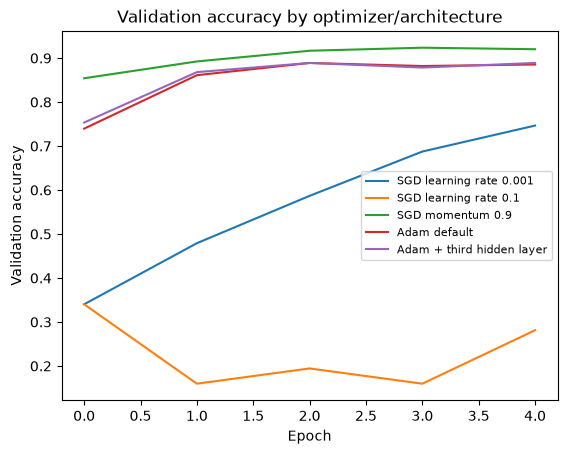

In [8]:
import pandas as pd
summary = pd.DataFrame(optimizer_trials).drop(columns='History')
display(summary.sort_values('Test accuracy', ascending=False))
for trial in optimizer_trials:
    plt.plot(trial['History'].history['val_accuracy'], label=trial['Setting'])
plt.title('Validation accuracy by optimizer/architecture')
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.legend(fontsize=8)
plt.show()

**Interpretation (general principles; check your actual table):** A very small learning rate tends to update weights slowly and may need more epochs. A larger one may learn faster, but excessively large learning rates can become unstable. Momentum can help smooth updates. Adam often converges quickly. An additional layer increases model capacity but does **not** guarantee improved test accuracy. Use the **measured table above** to say which performed best in this run.

## 6. Forward pass and generalization

Check that each prediction contains ten probabilities summing to approximately one; compare the most confident predictions.

Tensor type: <class 'tensorflow.python.framework.ops.EagerTensor'>
Shape: (360, 10)
Probability sums (first five): [0.99999994 1.         1.         1.         1.0000001 ]


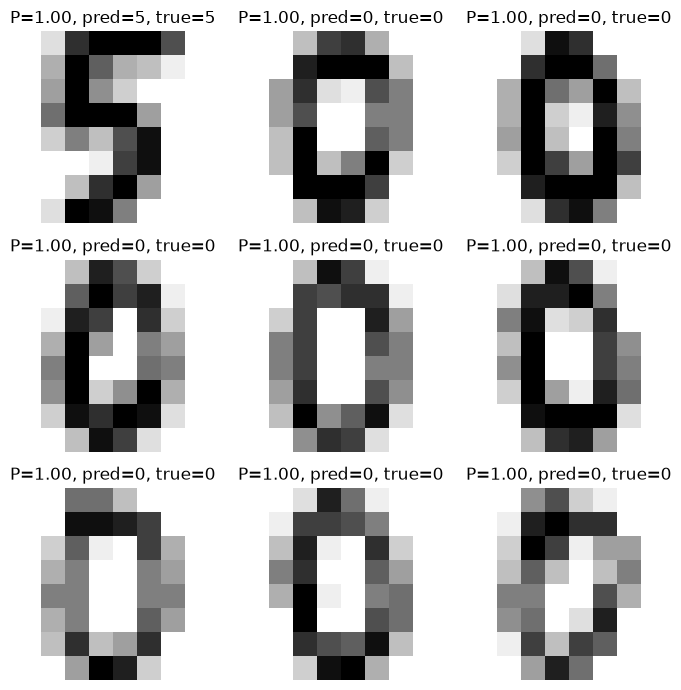

In [9]:
predictions_tf = adam_model(X_test)
print('Tensor type:', type(predictions_tf))
print('Shape:', predictions_tf.shape)
print('Probability sums (first five):', tf.reduce_sum(predictions_tf, axis=1)[:5].numpy())
predicted_labels_tf = tf.argmax(predictions_tf, axis=1)
confidence = tf.reduce_max(predictions_tf, axis=1).numpy()
confident_indices = np.argsort(confidence)[::-1][:9]
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for idx, ax in zip(confident_indices, axes.flat):
    ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'P={confidence[idx]:.2f}, pred={predicted_labels_tf[idx].numpy()}, true={y_test_raw[idx]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 7. Completed exercises: Impact of weight initialization

Test tiny, large, very large and all-zero weights using SGD, SGD with momentum and Adam. The target is to see **observed outcomes** rather than assume a fixed score.

In [10]:
def build_initialization_model(scale):
    def new_init():
        if scale == 'zeros':
            return tf.keras.initializers.Zeros()
        return tf.keras.initializers.TruncatedNormal(stddev=float(scale))
    return Sequential([
        Input(shape=(64,)),
        Dense(64, activation='tanh', kernel_initializer=new_init()),
        Dense(64, activation='tanh', kernel_initializer=new_init()),
        Dense(10, activation='softmax', kernel_initializer=new_init()),
    ])

initialization_results = []
for label, scale in [('tiny 0.001', 0.001), ('large 1', 1.0),
                     ('very large 10', 10.0), ('zero weights', 'zeros')]:
    for opt_label in ('SGD', 'momentum', 'Adam'):
        candidate = build_initialization_model(scale)
        optimizer = (SGD(learning_rate=0.1) if opt_label == 'SGD' else
                     SGD(learning_rate=0.1, momentum=0.9) if opt_label == 'momentum'
                     else Adam(learning_rate=0.001))
        candidate.compile(optimizer=optimizer,
                          loss='categorical_crossentropy', metrics=['accuracy'])
        candidate.fit(X_train, y_train, epochs=3, batch_size=32, verbose=0)
        test_loss, test_acc = candidate.evaluate(X_test, y_test, verbose=0)
        initialization_results.append({'Initialization': label, 'Optimizer': opt_label,
                                       'Test loss': test_loss, 'Test accuracy': test_acc})
        print(label, opt_label, f'accuracy={test_acc:.3f}')
display(pd.DataFrame(initialization_results).pivot(index='Initialization',
               columns='Optimizer', values='Test accuracy'))

tiny 0.001 SGD accuracy=0.103
tiny 0.001 momentum accuracy=0.325
tiny 0.001 Adam accuracy=0.731
large 1 SGD accuracy=0.697
large 1 momentum accuracy=0.219
large 1 Adam accuracy=0.228
very large 10 SGD accuracy=0.117
very large 10 momentum accuracy=0.133
very large 10 Adam accuracy=0.086
zero weights SGD accuracy=0.103
zero weights momentum accuracy=0.100
zero weights Adam accuracy=0.100


Optimizer,Adam,SGD,momentum
Initialization,,,
large 1,0.227778,0.697222,0.219444
tiny 0.001,0.730556,0.102778,0.325000
very large 10,0.086111,0.116667,0.133333
zero weights,0.100000,0.102778,0.100000


**Answers to initialization questions:** Extremely small weights can produce weak hidden activations and slow learning. Extremely large weights can saturate `tanh`, causing small derivatives and difficult optimization. Setting **all** weights to zero prevents hidden units in the same layer from learning distinct features (symmetry problem). Momentum and Adam can help optimization, but neither reliably fixes the symmetry caused by all-zero initialization. Compare the observed test accuracies before reaching a conclusion for this specific run.